The purpose of this Jupyter notebook is just to explain and visualize our neuropixel and widefield data.

The datasets studied here include a $560\times 560$ pixel widefield calcium imaging video of the mouse brain and simultaneous neuropixel recordings of 336 neurons from the V1 cortex. Entry $i,j$ of the neuropixel data matrix is the number of times neuron $j$ fired during time bin $i$. There are 115379 time points in each data with a timestep of $dt=0.0285s$ between each time point, for a total recording time of about 54.8 minutes. Several different experiments were done during this time period. There is a natural image experiment from bin 5480 to bin 58555, a receptive field mapping experiment from bin 59655 to bin 73781, and a linearity test experiment from bin 74975 to bin 107827.

A rank $500$ truncated SVD $X\approx U\Sigma V^T$ has been performed on the widefield data allowing us to separate it into spatial components $U\in\mathbb{R}^{560^2\times 500}$ and temporal components $\Sigma V^T\in\mathbb{R}^{500\times 115379}.$

In addition to the raw and widefield and neuropixel data, I also created a smoothened neuropixel data set by averaging each neuron over overlapping time windows of 35 time bins. As $1/0.0285\approx 35$, this approximately converts our neuropixel data into spikes/second data.

Let's start by importing packages.

In [1]:
import numpy as np # Matrix/vector computations
import matplotlib.pylab as plt # Plotting
from sklearn.preprocessing import StandardScaler # For subtracting out means/optionally normalizing STDs
plt.rcParams['figure.dpi']=400 # Increase resolution of figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

Next we do preprocessing, subtracting out the means of our data.

In [2]:
# Load and standardize data

# Neuropixel data
neuropixeldata   = np.load("spikes_v1_clean.npy").T # Load Neuropixel Data
std_neuropixel   = StandardScaler(with_std=False)
neuropixeldata   = std_neuropixel.fit_transform(neuropixeldata) # Subtract mean
num_times        = neuropixeldata.shape[0]
# Wide field data temporal components
widefielddata    = np.load("svdTemporalComponents_corr.npy") # Load Widefield data
sigma            = np.linalg.norm(widefielddata,axis=0)
V                = widefielddata / sigma # Separate Sigma*V^T into Sigma and V^T
std_V            = StandardScaler(with_std=False)
V                = std_V.fit_transform(V) # Subtract mean
# Create firing rates
num_bins = num_times-35 # Create bins of width 35
rates    = np.zeros((num_bins,336))
for i in np.arange(num_bins):
    rates[i] = np.sum(neuropixeldata[i:i+35,:],axis=0)/35 # Average over sliding time window
rates = StandardScaler(with_std=False).fit_transform(rates) # Subtract mean

# Save memory by clearing Sigma*V^T from memory and standardscalers,
# as we already have Sigma and V^T and the transformed datasets in their own variables
del widefielddata
del std_neuropixel
del std_V

The widefield temporal components are the easiest to plot, as they are just continuous functions evolving over time. The below plot shows the top ten components of $V$ over time bins $1000-2000$, when no experiments were happening yet. However, the y-axis doesn't have a clear interpretation in this case.

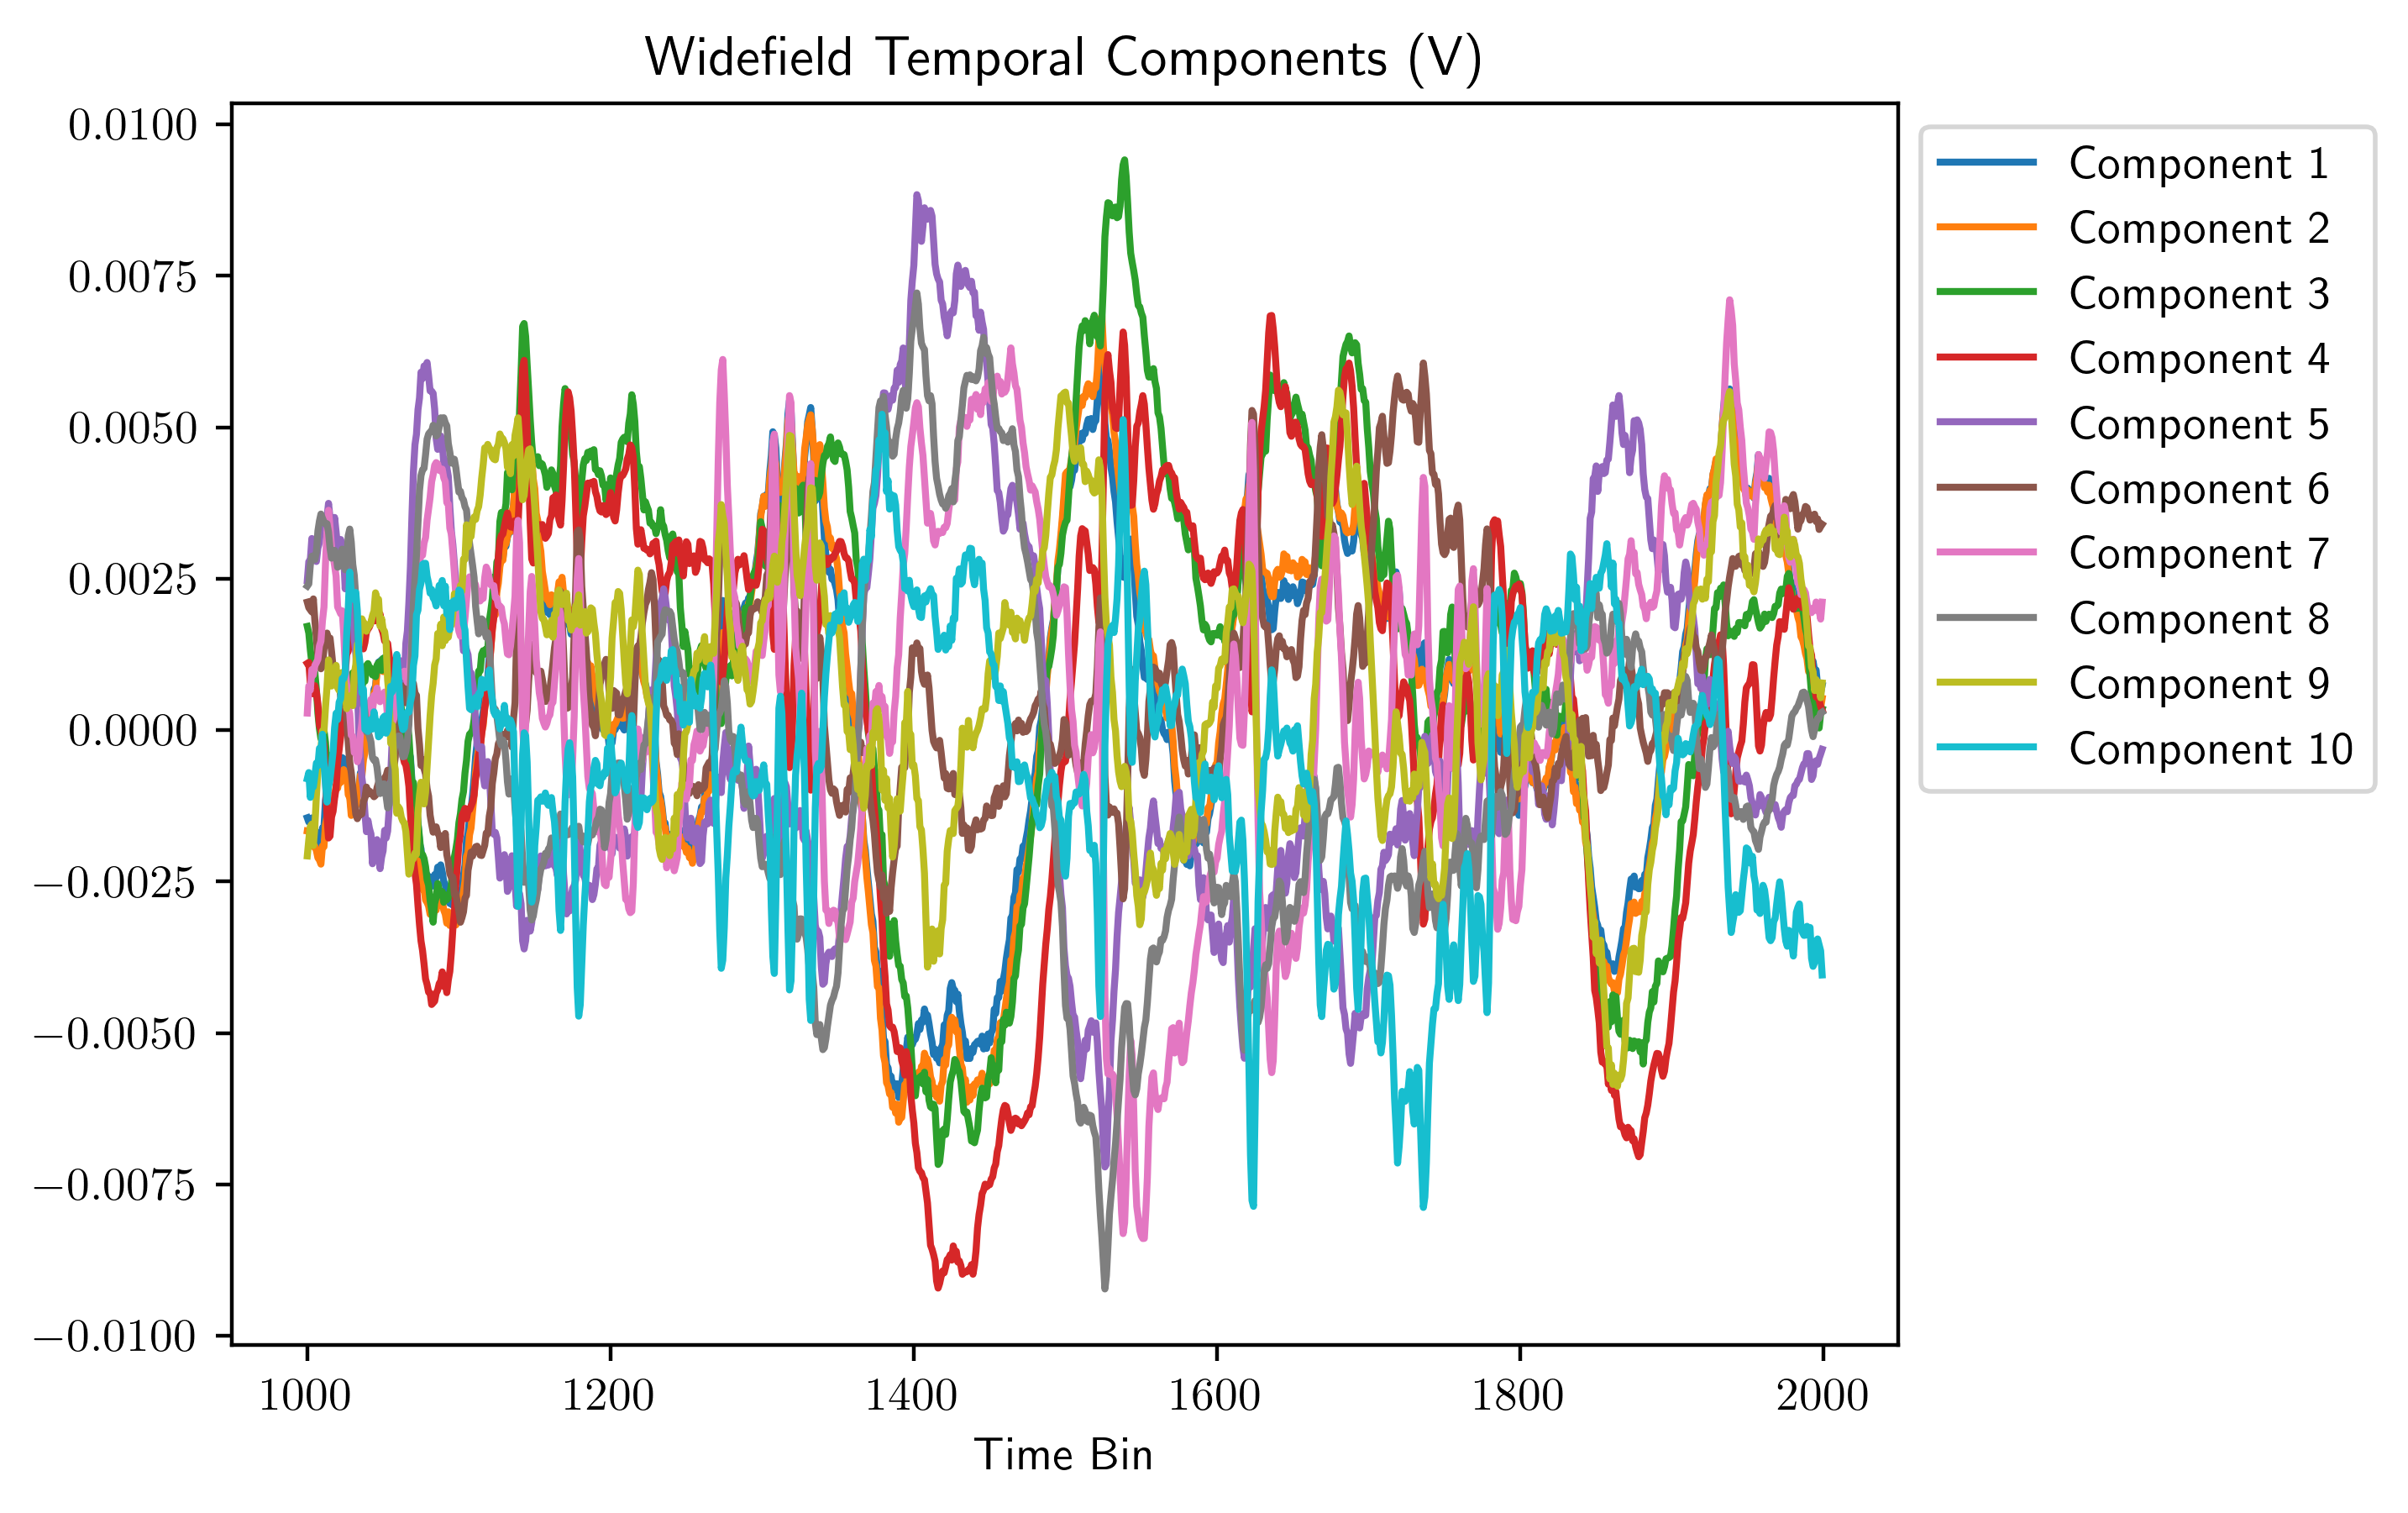

In [7]:
for i in range(10):
    plt.plot(np.arange(1000,2000),V[1000:2000,i],label="Component " + str(i+1))
plt.xlabel("Time Bin")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("Widefield Temporal Components (V)");

A more interesting way to visualize the widefield data is to reconstruct the video that it came from. We'll compute the 1000th column of $X=U\Sigma V^T$, corresponding to the 1000th time point.

In [3]:
wf_spat = np.load('wf_vid.npy') # Load spatial components. Warning: This will use 2.5GB of RAM.
wf_spat = wf_spat[:,:,:20] # Keep only the top 20 cohtomponents
USV = wf_spat@(sigma[:20]*V[1000,:20]).T # Reconstruct the data at time point 1000 with 20 components
del wf_spat # Clear this very large array from memory
plt.rcParams['figure.dpi']=80 # Let's make this particular figure smaller

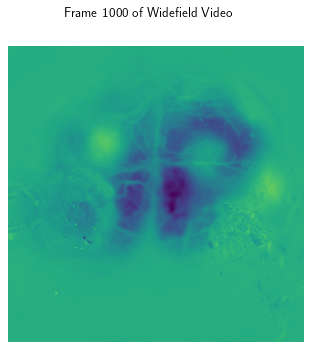

In [4]:
fig,ax = plt.subplots()
ax.imshow(USV)
ax.axis('off')
fig.suptitle("Frame 1000 of Widefield Video");
plt.rcParams['figure.dpi']=400 # Increase resolution of other figures

For the neuropixel data, it makes the most sense to show the data as a raster plot. It seems like it should be possible to color the entries of the raster plot based on how many spikes occur in each bin; however, I am not sure how to do this in matplotlib yet. The raster plot below just shows a dot wherever at least one spike occurred.

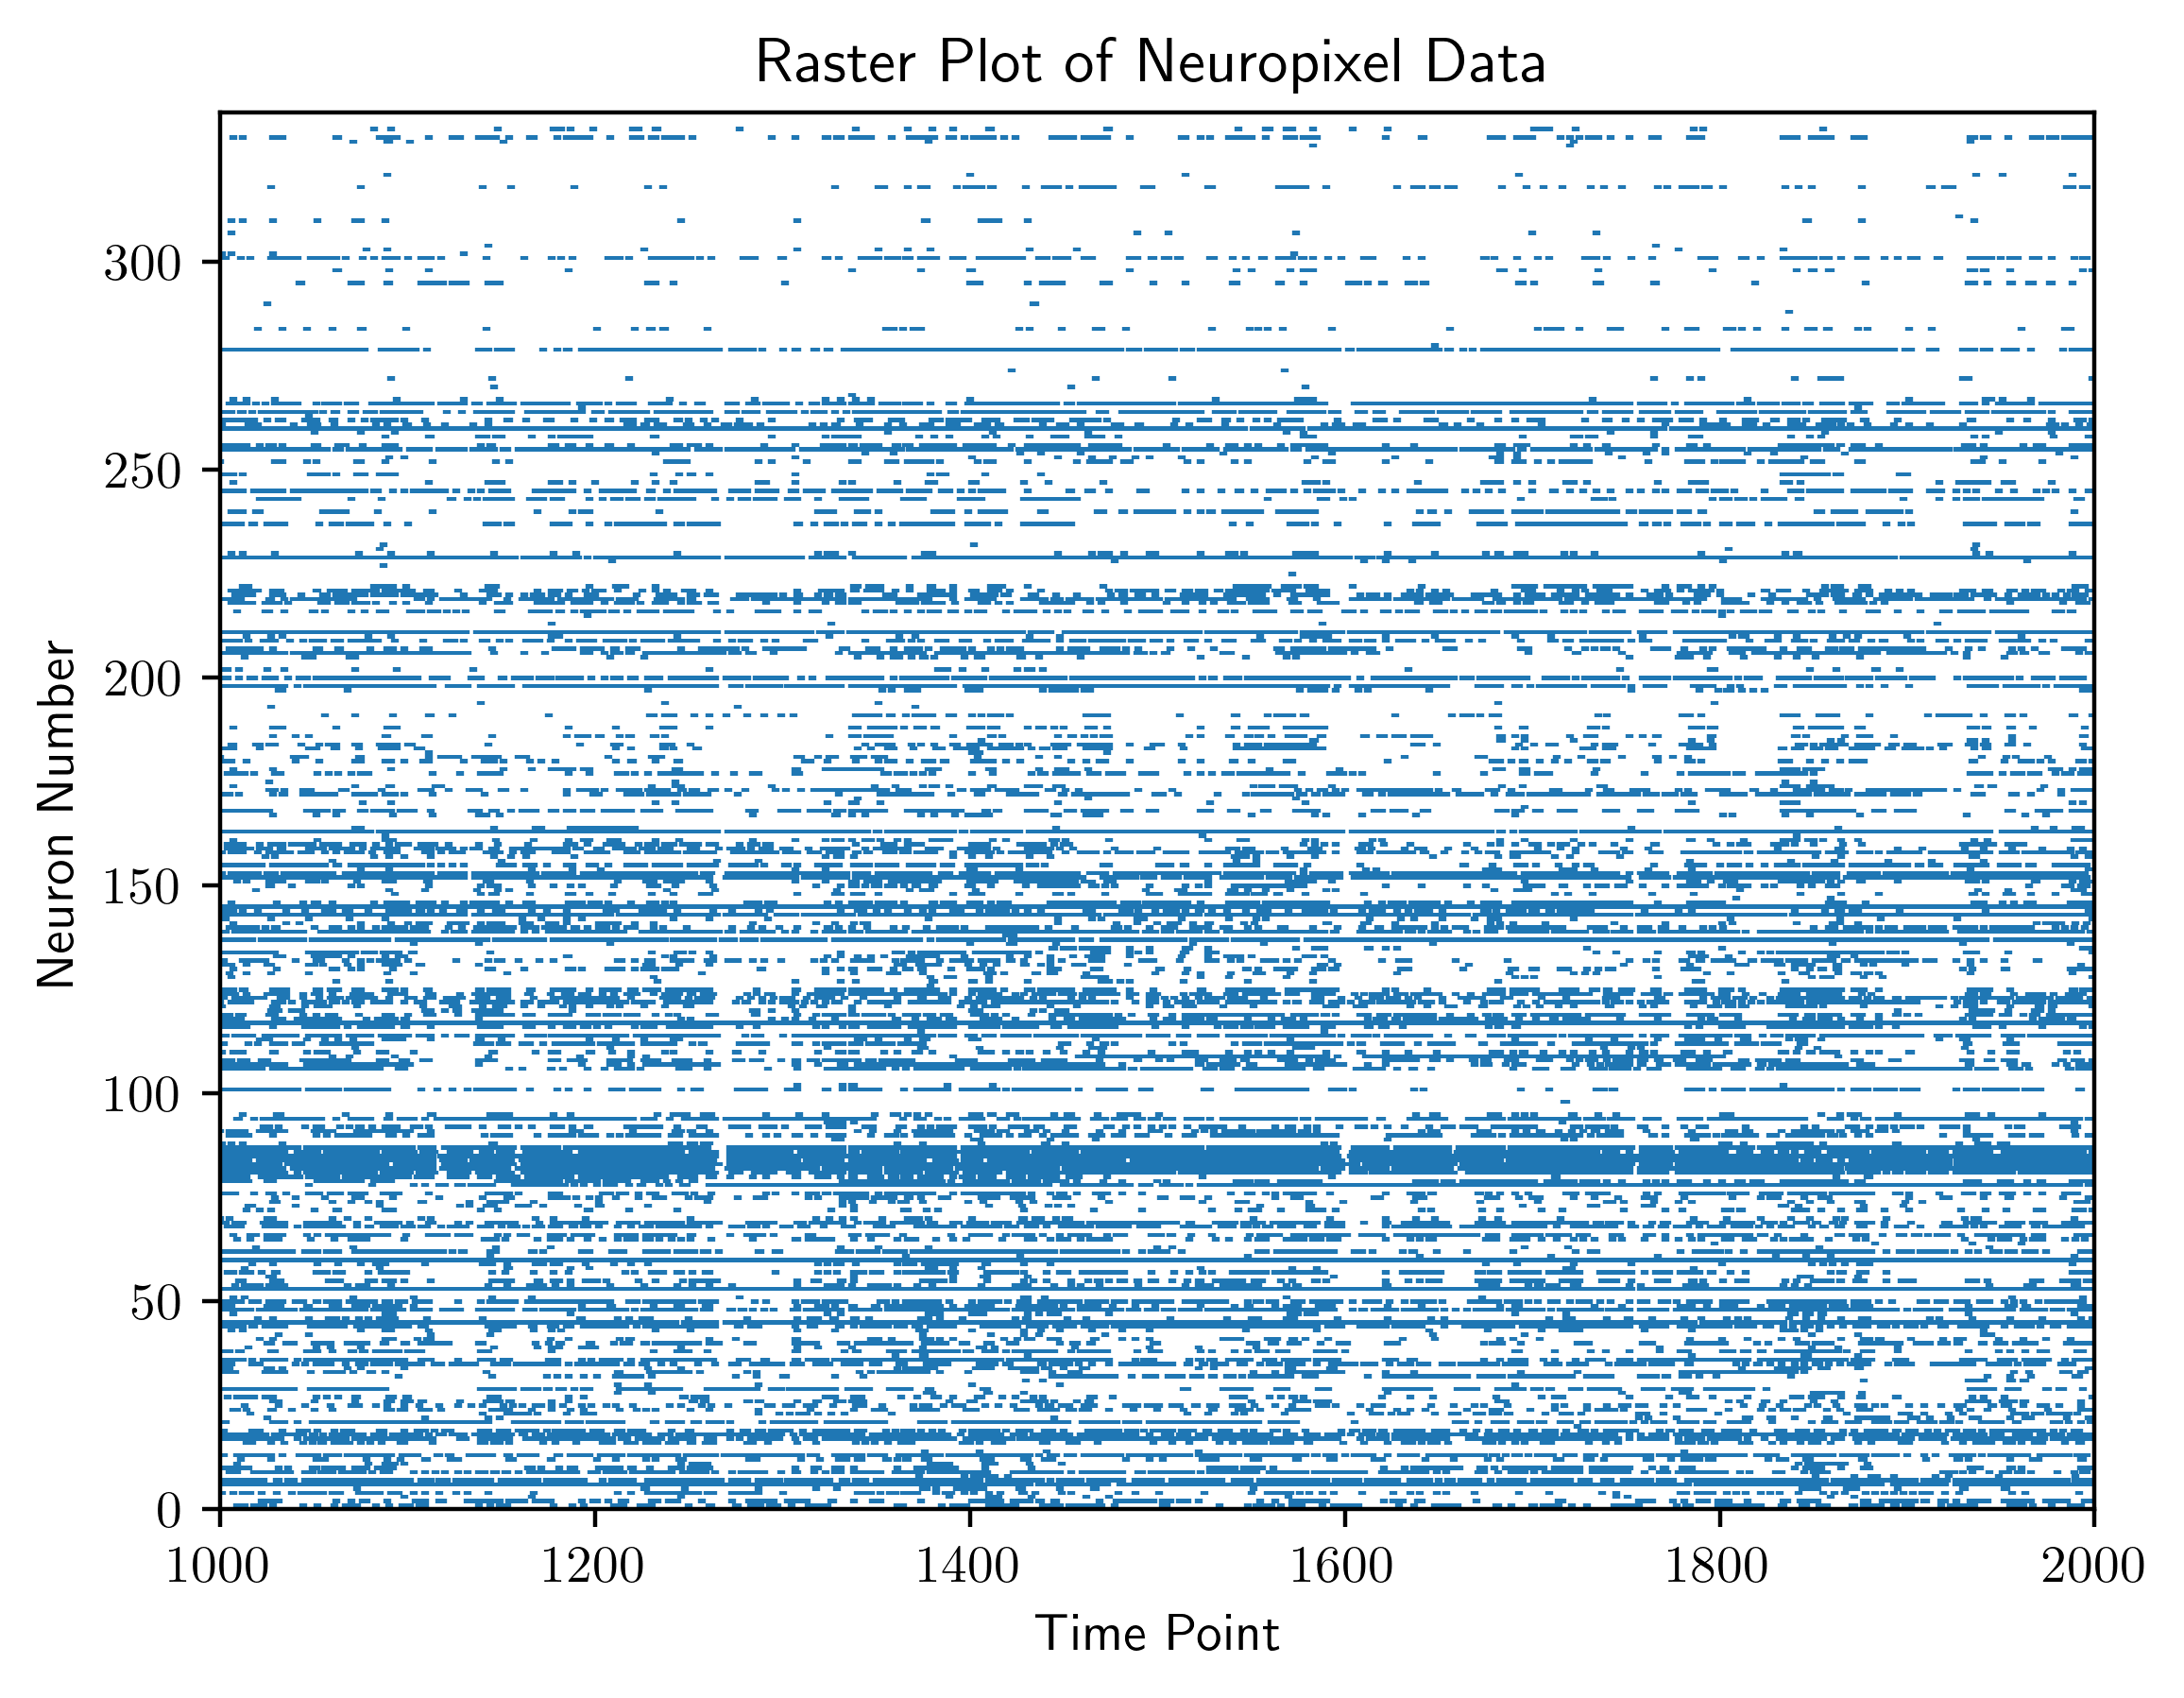

In [5]:
# Convert neuropixel array into array of ones (spikes) or zeroes (no spikes)
# Also put time on horizontal axis
spikes = (np.round(neuropixeldata).astype(int)>0).T
spikes = spikes.astype(int) # Convert from true/false matrix to 1/0 matrix
indexes = np.tile(np.arange(115379),(336,1)) # Create matrix whose jth column consists of just j's
spikes *= indexes # Convert from 1/0 matrix to matrix whose nonzero indices are the times spikes occurred
plt.eventplot(spikes[:,1000:2000])
plt.xlim(1000,2000)
plt.ylim(0,336)
plt.xlabel("Time Point")
plt.ylabel("Neuron Number")
plt.title("Raster Plot of Neuropixel Data");

Finally, we can visualize the firing rate data for individual neurons with simple time series plots. The below plot shows the firing rates for the first 5 neurons, again from time points 1000 to time points 2000.

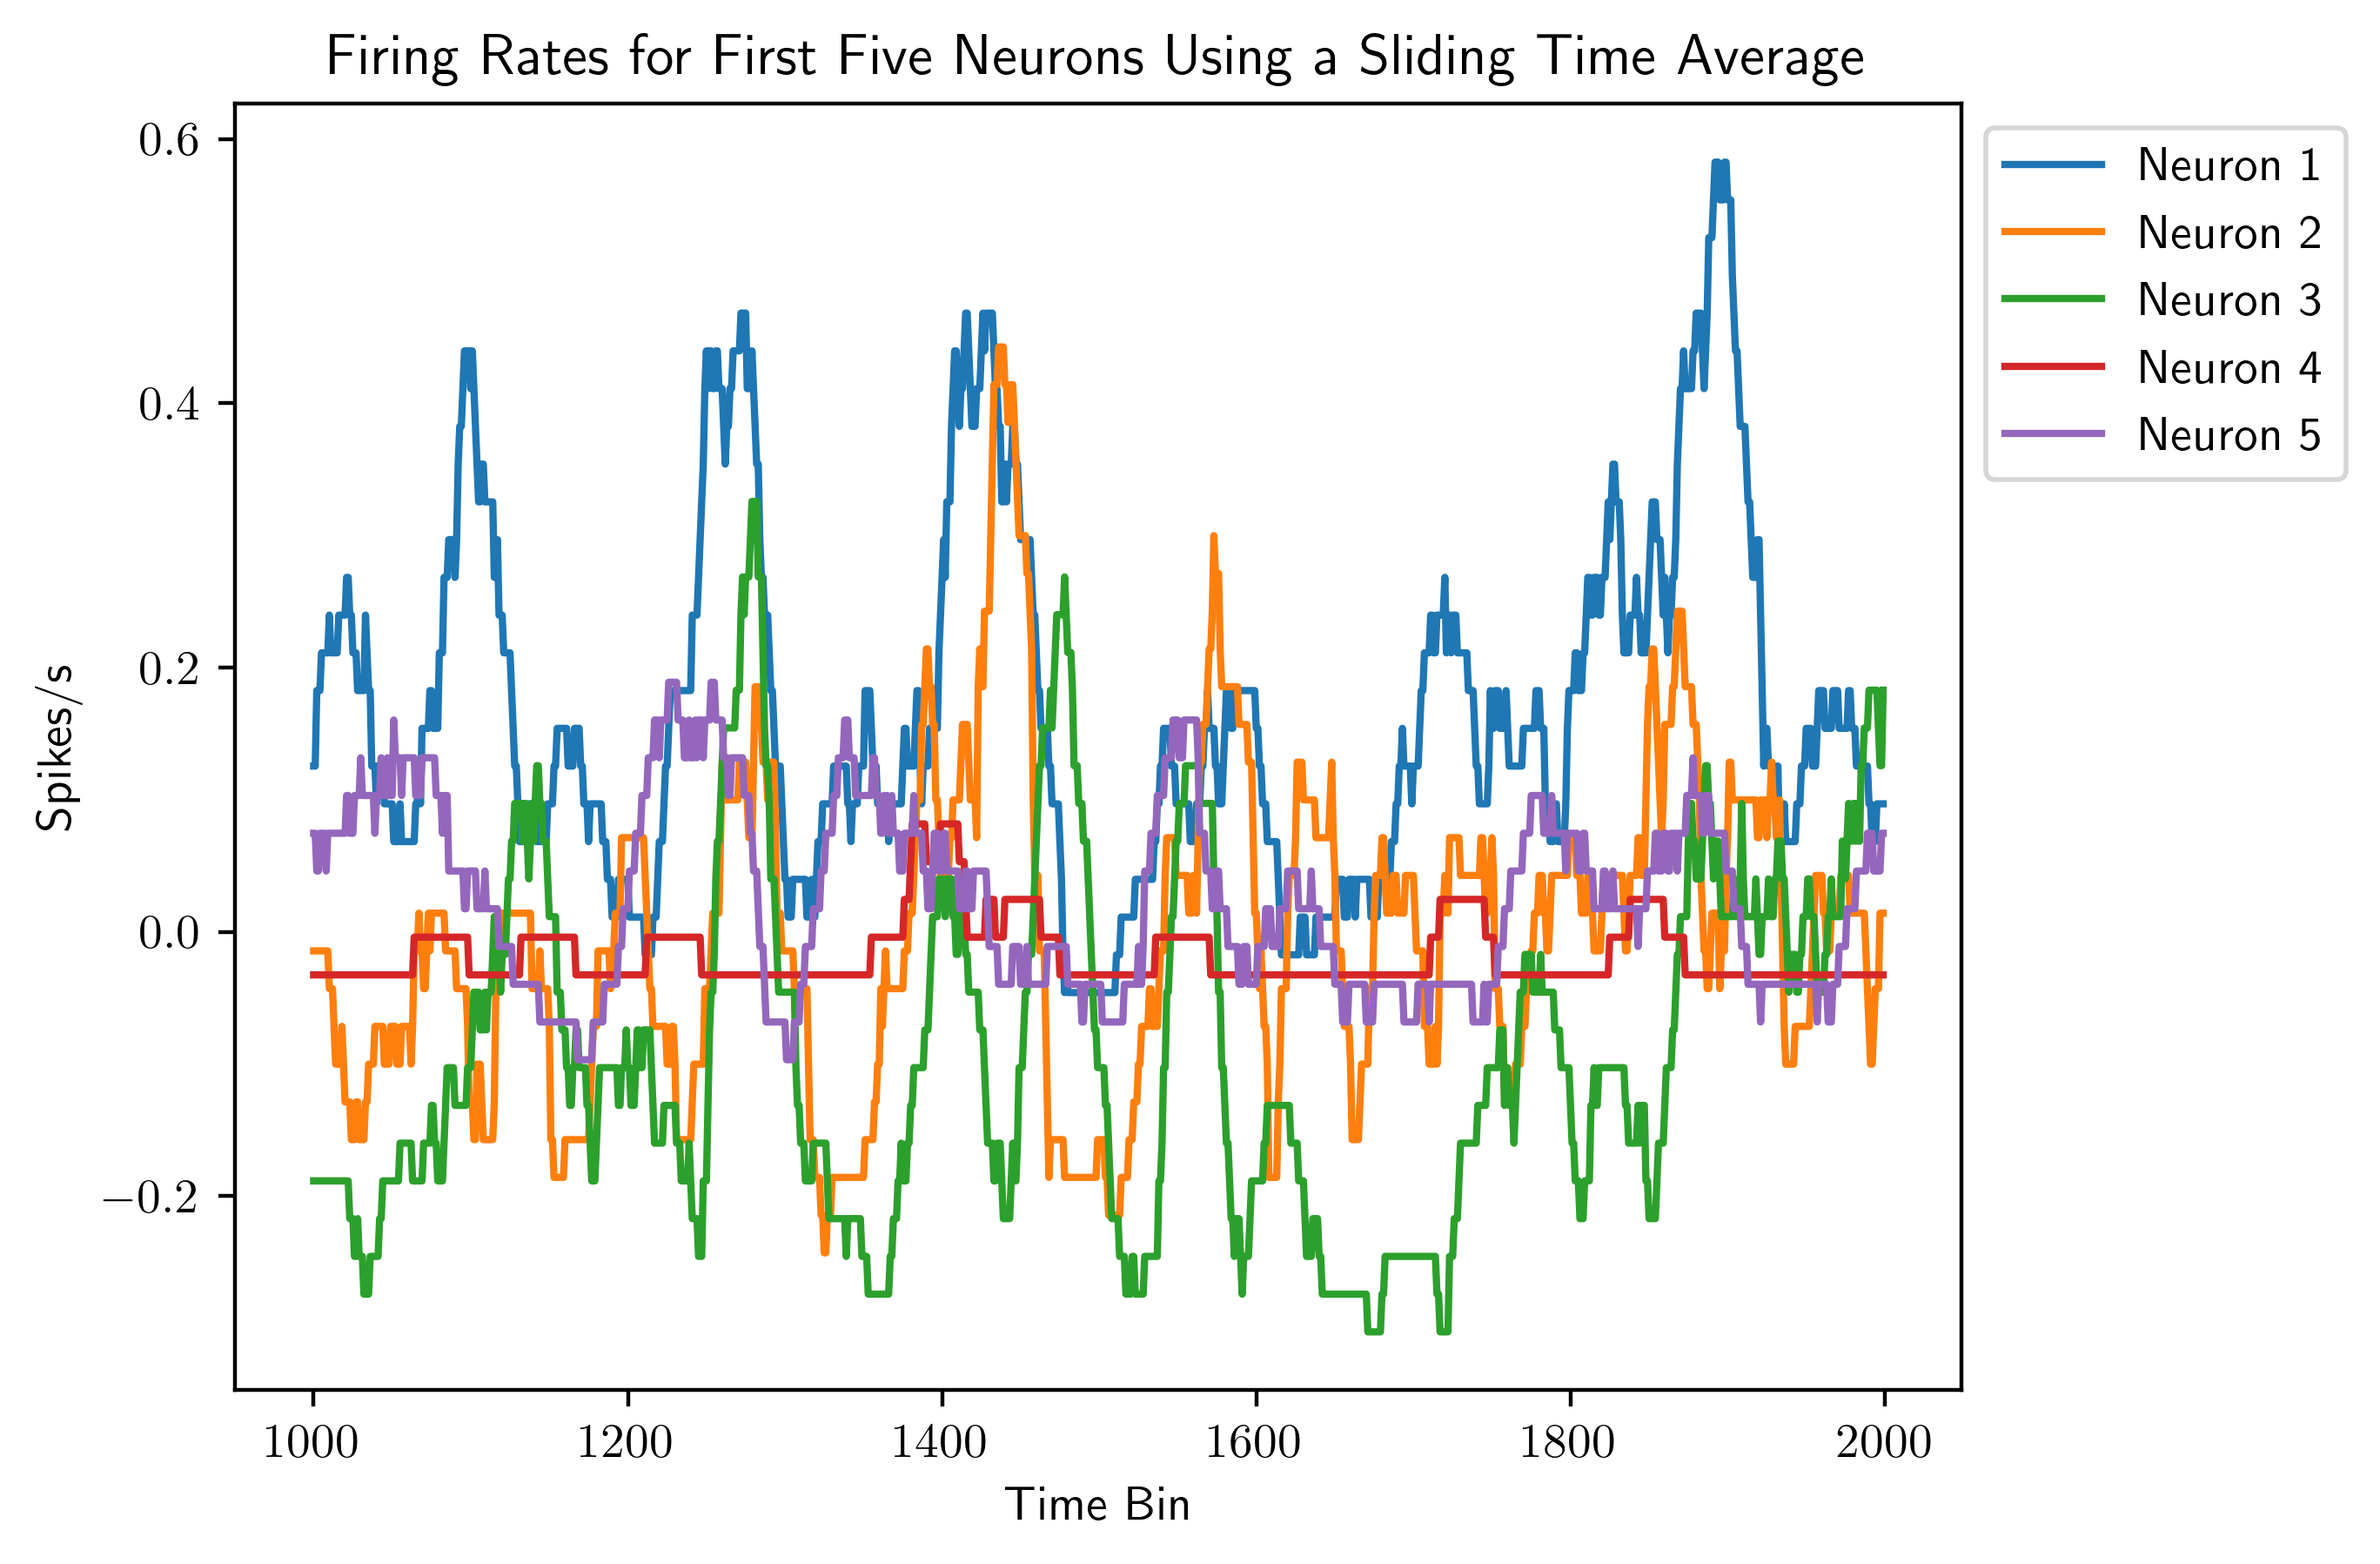

In [13]:
for i in range(5):
    plt.plot(np.arange(1000,2000),rates[1000:2000,i],label="Neuron " + str(i+1))
    plt.xlabel("Time Bin")
    plt.ylabel("Spikes/s")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("Firing Rates for First Five Neurons Using a Sliding Time Average");